### ERA5 Surface Characteristics and Grid Structure Around Svalbard
**Learning Objectives**:

By the end of this exercise, you should be able to:

1. Open a NetCDF file using Python and Xarray.
2. Inspect dimensions, coordinates, and variables.
3. Understand the structure of the ERA5 grid.
4. Plot the ERA5 grid around Svalbard.
5. Visualize land-sea mask and terrain height.
6. Discuss the limitations of coarse-resolution datasets in complex terrain.

In [14]:
# First run this cell to  import required libraries
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

### 1. Introduction

ERA5 is a global atmospheric reanalysis produced by the European Centre for Medium-Range Weather Forecasts (ECMWF)\
In this exercise, you will work with an ERA5 constants file containing variables that do not change with time, such as:

1. Land-sea mask (lsm)
2. Surface geopotential (z)

You will investigate how these variables are represented on the ERA5 grid around Svalbard.

### 2. Load model data

In [ ]:
# file = '/Users/irms/Library/CloudStorage/OneDrive-UniversityofBergen/UniB/UNIS/teaching/excersises/era5_constants.nc'
file = 'your file path'
# "../data/era5_constants.nc"
ds = xr.open_dataset(file)
ds

***Questions***

1. What are the dimensions of the dataset?
2. Which coordinates are available?
3. Which variables are available? 

### Explore the data set

In [ ]:
# print(ds)
# list(ds.data_vars)

***Questions***
1. What does the variable lsm represent?
2. What does the variable z represent?
3. What are the units of z?

### Examine the Coordinates

Display the latitude and longitude coordinates.

In [16]:
print(ds.latitude)

<xarray.DataArray 'latitude' (latitude: 721)> Size: 6kB
array([ 90.  ,  89.75,  89.5 , ..., -89.5 , -89.75, -90.  ])
Coordinates:
  * latitude  (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
    number    int64 8B ...
    expver    <U4 16B ...
Attributes:
    units:             degrees_north
    standard_name:     latitude
    long_name:         latitude
    stored_direction:  decreasing

In [17]:
print("Latitude range:")
print(ds.latitude.max().values,
      ds.latitude.min().values)

print("Longitude range:")
print(ds.longitude.min().values,
      ds.longitude.max().values)

Latitude range:
90.0 -90.0
Longitude range:
0.0 359.75


### Investigating ERA5 Grid Spacing

In [18]:
dlat = abs(ds.latitude[1] - ds.latitude[0])
dlon = abs(ds.longitude[1] - ds.longitude[0])

print("Latitude spacing:", float(dlat))
print("Longitude spacing:", float(dlon))

Latitude spacing: 0.25
Longitude spacing: 0.25


****Questions****
1. What is the ERA5 grid spacing?
2. Is the spacing the same everywhere on Earth?

### Extract a Svalbard Subset

To make plotting faster, extract a smaller region around Svalbard.

In [ ]:
subset = ds.sel( # Svalbard
    longitude=slice(5, 35),
    latitude=slice(82, 74)
)
subset

### Plot the Land-Sea Mask

The land-sea mask indicates the fraction of a grid cell covered by land.

In [ ]:
subset["lsm"].plot(
    cmap="Blues",
    figsize=(10,7)
)

plt.title("ERA5 Land-Sea Mask Around Svalbard")
plt.show()

### Terrain Height

ERA5 stores surface geopotential ($z$) rather than height.

Height can be approximated using:

$$H = \frac{z}{g}$$

where:
* $g = 9.80665 \text{ m s}^{-2}$

****Question****
Why do we use geopotential rather than geometric height?


### Calculate Terrain Height

In [ ]:
terrain = subset["z"].copy() / 9.80665
# update metadata
terrain.attrs = {} # why this line?
terrain.attrs["units"] = "m"
terrain.attrs["long_name"] = "Terrain height"
terrain

### Visualising ERA5 Grid Points and Terrain Height
Create a plot of all grid-cell centres around Svalbard.

In [ ]:
terrain.plot(
    cmap="terrain",
    figsize=(10,7)
)

plt.title("ERA5 Terrain Height Around Svalbard")
plt.show()

### Zoom in to Adventdalen

****Questions****
1. What altitude is Longyearbyen and Adventdalen according to Era5



In [ ]:
subset = ds.sel( # Adventdalen
    longitude=slice(14, 17),
    latitude=slice(78.5, 78)
)
terrain = subset["z"].copy() / 9.80665
# update metadata
terrain.attrs = {} # why this line?
terrain.attrs["units"] = "m"
terrain.attrs["long_name"] = "Terrain height"
terrain

### Orthographic Map Projection

have a look at different projection options for map plotting:\
https://scitools.org.uk/cartopy/docs/v0.15/crs/projections.html

In [ ]:
fig = plt.figure(figsize=(10,10))

ax = plt.axes(
    projection=ccrs.Orthographic(
        central_longitude=15.5,
        central_latitude=78
    )
)

terrain.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="terrain",
    add_colorbar=True
)

lon2d, lat2d = np.meshgrid(
    terrain.longitude,
    terrain.latitude
)

ax.scatter(
    lon2d,
    lat2d,
    s=5,
    color="red",
    transform=ccrs.PlateCarree(),
    zorder=10
)
ax.scatter(
    15.465,
    78.246,
    color="yellow",
    edgecolor="black",
    s=150,
    transform=ccrs.PlateCarree()
)

ax.text(
    15.53,
    78.26,
    "Longyearbyen",
    transform=ccrs.PlateCarree()
)

ax.coastlines()
ax.gridlines()
# ax = plt.axes(projection=ccrs.PlateCarree())

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.5,
    color="gray",
    linestyle="--"
)

gl.top_labels = False
gl.right_labels = False

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.title("ERA5 Terrain Height Around Svalbard")
plt.show()

Estimate the terrain height nearest to Longyearbyen Airport.\
Latitude: 78.246°
Longitude: 15.465°

****Question****
Is the closest model gridpoint representative for your location?

In [ ]:
terrain.sel(
    latitude=78.246,
    longitude=15.465,
    method="nearest"
)

### Land Sea around Longyearbyen

In [ ]:
fig = plt.figure(figsize=(10,10))

ax = plt.axes(
    projection=ccrs.Orthographic(
        central_longitude=15.5,
        central_latitude=78
    )
)
subset["lsm"].plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="Blues",
    # figsize=(10,7)
)


lon2d, lat2d = np.meshgrid(
    terrain.longitude,
    terrain.latitude
)

ax.scatter(
    lon2d,
    lat2d,
    s=5,
    color="red",
    transform=ccrs.PlateCarree(),
    zorder=10
)
ax.scatter(
    15.465,
    78.246,
    color="yellow",
    edgecolor="black",
    s=150,
    transform=ccrs.PlateCarree()
)

ax.text(
    15.53,
    78.26,
    "Longyearbyen",
    transform=ccrs.PlateCarree()
)

ax.coastlines(resolution='10m')
ax.gridlines()
# ax = plt.axes(projection=ccrs.PlateCarree())

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.5,
    color="gray",
    linestyle="--"
)

gl.top_labels = False
gl.right_labels = False

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.title("ERA5 Terrain Height Around Svalbard")
plt.show()

****Question***
Is Adventdalen sea or land according to ERA5 and what does this mean?

### CARRA reanalysis

1. Explore the CARRA dataset, what is different from ERA5?
2. extract (slice) a time and location 
3. Plot vertical proifles and cross section in the Adventdalen area

In [ ]:
file = '/Users/irms/Library/CloudStorage/OneDrive-UniversityofBergen/UniB/UNIS/teaching/excersises/CARRA.nc'
# file = 'your file path'
ds = xr.open_dataset(file)
ds.variables

orog_file = '/Users/irms/Library/CloudStorage/OneDrive-UniversityofBergen/UniB/UNIS/teaching/excersises/CARRA_orog.nc'



Frozen({'pres': <xarray.Variable (valid_time: 4, heightAboveGround: 11, y: 989, x: 789)> Size: 137MB
[34334124 values with dtype=float32]
Attributes: (12/34)
    GRIB_paramId:                             54
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      780321
    GRIB_typeOfLevel:                         heightAboveGround
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_name:                                Pressure
    GRIB_shortName:                           pres
    GRIB_units:                               Pa
    long_name:                                Pressure
    units:                                    Pa
    standard_name:                            unknown, 'clwc': <xarray.Variable (valid_time: 4, heightAboveGround: 11, y: 989, x: 789)> Size: 137MB
[34334124 values with dtype=float32]
Attributes: (12/34)
    GRIB_pa

In [26]:
# First time, lowest level
ws = ds["ws"].isel(valid_time=0, heightAboveGround=0)
wdir = ds["wdir"].isel(valid_time=0, heightAboveGround=0)

lon = ds["longitude"]
lat = ds["latitude"]
u = -ws * np.sin(np.deg2rad(wdir))
v = -ws * np.cos(np.deg2rad(wdir))


/opt/homebrew/anaconda3/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1762: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  result = super().pcolormesh(*args, **kwargs)
/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)
/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)


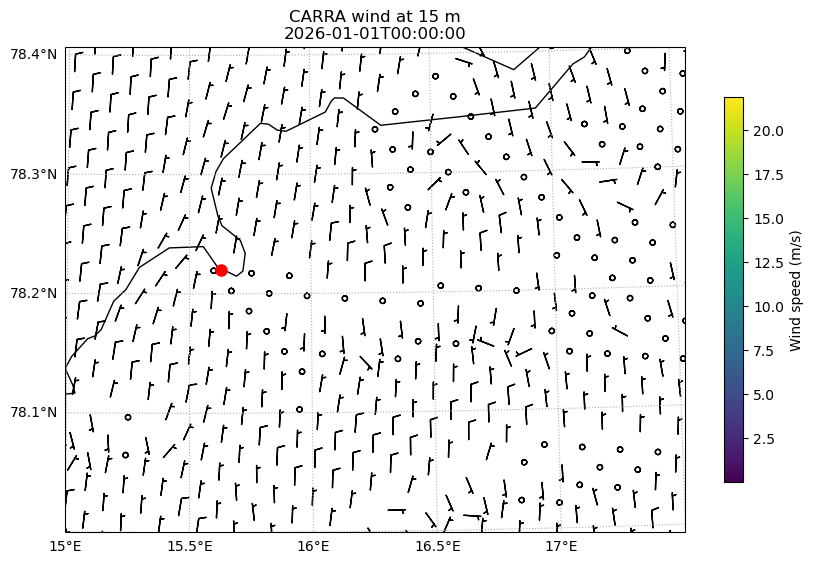

In [38]:
fig = plt.figure(figsize=(10, 10))
# ax = plt.axes(projection=ccrs.PlateCarree())

ax = plt.axes(
    projection=ccrs.Orthographic(
        central_longitude=15.5,
        central_latitude=78
    )
)

# wind speed shading
pcm = ax.pcolormesh(
    lon,
    lat,
    ws,
    cmap="viridis",
    shading="auto"
)


cbar = plt.colorbar(
    pcm,
    ax=ax,
    shrink=0.5

)

cbar.set_label("Wind speed (m/s)")

# reduce barb density
skip = 1

ax.barbs(
    lon.values[::skip, ::skip],
    lat.values[::skip, ::skip],
    u.values[::skip, ::skip],
    v.values[::skip, ::skip],
    length=5,
    transform=ccrs.PlateCarree()
)

ax.coastlines(resolution="10m")

gl = ax.gridlines(
    draw_labels=True,
    linestyle=":"
)

gl.top_labels = False
gl.right_labels = False

plt.title(
    f"CARRA wind at {float(ds.heightAboveGround[0]):.0f} m\n"
    f"{str(ds.valid_time.values[0])[:19]}"
)
ax.set_extent(
    [15.0, 17.5,   # lon min/max
     78.0, 78.4], # lat min/max
    crs=ccrs.PlateCarree()
)
# Plot marker for Longyearbyen
ax.plot(
    15.63, 78.22,
    "ro",
    markersize=8,
    transform=ccrs.PlateCarree()
)

plt.show()

### Cross section

In [45]:
# along
# start_lon, start_lat = 15.2, 78.23
# end_lon, end_lat = 16.4, 78.16

# accross
start_lon, start_lat = 15.7, 78.13   # SW side
end_lon,   end_lat   = 16.2, 78.28   # NE side

/opt/homebrew/anaconda3/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1762: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  result = super().pcolormesh(*args, **kwargs)
/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)
/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)


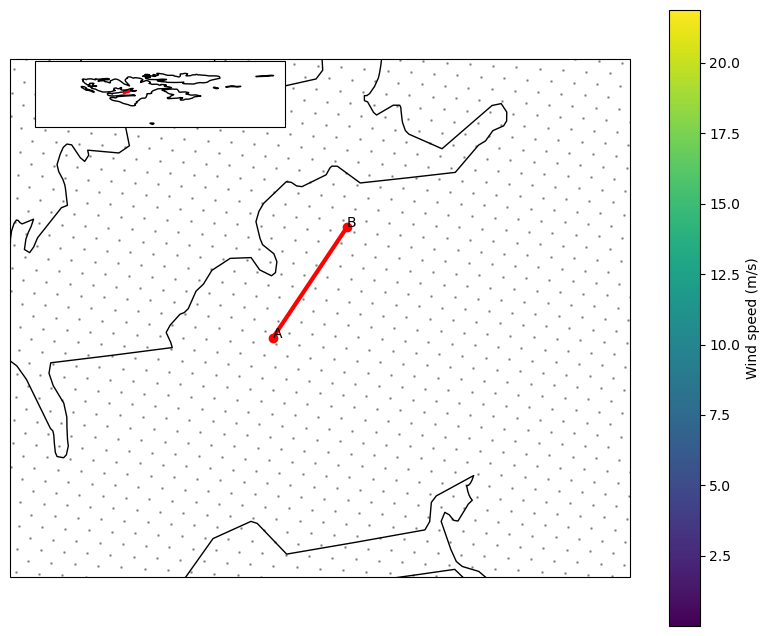

In [47]:
fig = plt.figure(figsize=(10,8))
ax = plt.axes(
    projection=ccrs.Orthographic(
        central_longitude=15.5,
        central_latitude=78
    )
)
pcm = ax.pcolormesh(
    ds.longitude,
    ds.latitude,
    ws,
    cmap="viridis",
    shading="auto"
)

plt.colorbar(pcm, ax=ax, label="Wind speed (m/s)")

ax.coastlines("10m")

ax.plot(
    [start_lon, end_lon],
    [start_lat, end_lat],
    color="red",
    linewidth=3,
    transform=ccrs.PlateCarree()
)

ax.plot(
    [start_lon, end_lon],
    [start_lat, end_lat],
    "ro",
    transform=ccrs.PlateCarree()
)

ax.text(
    start_lon,
    start_lat,
    "A",
    transform=ccrs.PlateCarree()
)

ax.text(
    end_lon,
    end_lat,
    "B",
    transform=ccrs.PlateCarree()
)

ax.set_extent([14,18,77.8,78.5])

###
import cartopy.crs as ccrs

axins = fig.add_axes(
    [0.15, 0.65, 0.25, 0.25],
    projection=ccrs.PlateCarree()
)

axins.coastlines(resolution="50m")

axins.set_extent([5, 35, 74, 82])

axins.plot(
    [start_lon, end_lon],
    [start_lat, end_lat],
    "r-",
    lw=2,
    transform=ccrs.PlateCarree()
)
ax.scatter(
    lon,
    lat,
    s=1,
    color="k",
    alpha=0.3,
    transform=ccrs.PlateCarree()
)

plt.show()

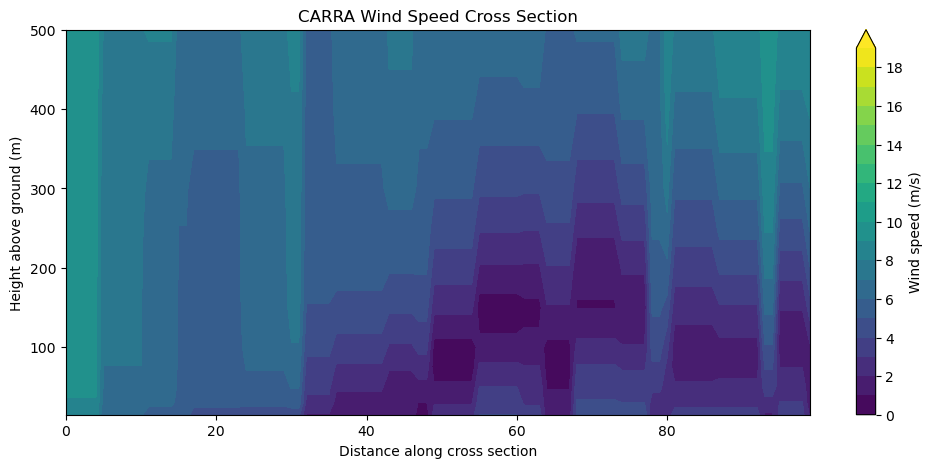

In [50]:
start_lon, start_lat = 15.2, 78.23
end_lon, end_lat = 16.4, 78.16

npts = 100

lon_line = np.linspace(start_lon, end_lon, npts)
lat_line = np.linspace(start_lat, end_lat, npts)

lon2d = ds.longitude.values
lat2d = ds.latitude.values

lon_flat = lon2d.ravel()
lat_flat = lat2d.ravel()

time_idx = 0

heights = ds.heightAboveGround.values

cross = np.zeros((len(heights), npts))

indices = []

for lon, lat in zip(lon_line, lat_line):

    dist = (lon_flat - lon)**2 + (lat_flat - lat)**2
    idx = np.argmin(dist)

    iy, ix = np.unravel_index(idx, lon2d.shape)

    indices.append((iy, ix))

cross = np.zeros((len(heights), npts))

for k in range(len(heights)):

    field = ds["ws"].isel(
        valid_time=0,
        heightAboveGround=k
    ).values

    for i, (iy, ix) in enumerate(indices):

        cross[k, i] = field[iy, ix]


fig, ax = plt.subplots(figsize=(12, 5))

cf = ax.contourf(
    np.arange(npts),
    heights,
    cross,
    levels=np.arange(0, 20, 1),
    cmap="viridis",
    extend="max"
)

plt.colorbar(
    cf,
    ax=ax,
    label="Wind speed (m/s)"
)

ax.set_ylabel("Height above ground (m)")
ax.set_xlabel("Distance along cross section")

ax.set_title("CARRA Wind Speed Cross Section")

plt.show()

In [52]:
ds

<xarray.Dataset> Size: 699MB
Dimensions:            (valid_time: 4, heightAboveGround: 11, y: 989, x: 789)
Coordinates:
  * valid_time         (valid_time) datetime64[ns] 32B 2026-01-01 ... 2026-07...
    expver             (valid_time) <U4 64B ...
  * heightAboveGround  (heightAboveGround) float64 88B 15.0 30.0 ... 400.0 500.0
    latitude           (y, x) float64 6MB 70.13 70.13 70.12 ... 67.34 67.32
    longitude          (y, x) float64 6MB 340.6 340.7 340.7 ... 64.65 64.64
Dimensions without coordinates: y, x
Data variables:
    pres               (valid_time, heightAboveGround, y, x) float32 137MB ...
    clwc               (valid_time, heightAboveGround, y, x) float32 137MB ...
    t                  (valid_time, heightAboveGround, y, x) float32 137MB ...
    wdir               (valid_time, heightAboveGround, y, x) float32 137MB ...
    ws                 (valid_time, heightAboveGround, y, x) float32 137MB ...
Attributes:
    GRIB_centre:             enmi
    GRIB_centreDescription:  Oslo
    GRIB_subCentre:          255
    Conventions:             CF-1.7
    institution:             Oslo
    history:                 2026-10-01T05:07 GRIB to CDM+CF via cfgrib-0.9.1...

In [54]:
print(ds.data_vars)

Data variables:
    pres     (valid_time, heightAboveGround, y, x) float32 137MB ...
    clwc     (valid_time, heightAboveGround, y, x) float32 137MB ...
    t        (valid_time, heightAboveGround, y, x) float32 137MB ...
    wdir     (valid_time, heightAboveGround, y, x) float32 137MB ...
    ws       (valid_time, heightAboveGround, y, x) float32 137MB ...
